# Prayat (ប្រយ័ត្ន) — Scam Message Detector for English, Khmer and Chinese

**Machine Learning Group Project**

*Prayat* means "be careful" in Khmer. The goal: paste (or screenshot) any SMS, Telegram or
chat message, in English, Khmer or Chinese, and get an instant answer:
**Scam**, **Spam / advert**, or **Normal**, plus the words that made the model suspicious.

| Step | What we do | Tools |
|---|---|---|
| 1 | Load three real datasets and our own Khmer dataset | Pandas, XML |
| 2 | Exploratory Data Analysis | Pandas, Matplotlib |
| 3 | Preprocessing: normalisation, placeholders, character n-grams, TF-IDF, encoding | scikit-learn |
| 4 | Models: Naive Bayes, Logistic Regression (word vs character), Neural Network (MLP) | scikit-learn |
| 5 | Evaluation: Accuracy, Precision, Recall, F1, confusion matrices, per language | scikit-learn, Matplotlib |
| 6 | Explainability and export for the web app | NumPy, JSON |

## 1. Setup

In [1]:
import json
import sys
import time
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from textprep import EMAIL, PHONE, URL, analyze, detect_language, normalize  # noqa: E402

RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
WEB = ROOT / "docs" / "model"
for d in (FIG, WEB):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)
LABELS = ["normal", "spam", "scam"]
LANGS = ["en", "km", "zh"]
LANG_NAMES = {"en": "English", "km": "Khmer", "zh": "Chinese"}
LABEL_COLORS = {"normal": "#2F9E6E", "spam": "#E0A21B", "scam": "#D6453D"}
MODEL_COLORS = {"Naive Bayes": "#A3ADBD", "LogReg (words)": "#7C8BA6", "LogReg (characters)": "#1F5F8B", "MLP (characters)": "#5BA3C9"}
INK = "#16202E"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", facecolor="white")

## 2. Load the data

| Language | Source | What it contains |
|---|---|---|
| English | **SMS Phishing Dataset** (Mishra & Soni, Mendeley Data, 2022) | 5,971 real SMS: ham, spam, smishing |
| Chinese | **FBS SMS Dataset** (Zhang et al., ACM CCS 2020) | ~14,000 real spam and fraud SMS sent from fake base stations in China, 14 categories |
| Chinese | **NUS SMS Corpus** (Chen & Kan, 2013) | 31,465 real personal SMS (normal messages) |
| Khmer, English, Chinese | **Authored by our group** (`data/authored/generate_authored.py`) | Template-based messages for common Cambodian scam patterns, adverts and everyday messages |

We use three classes: **normal**, **spam** (unwanted adverts, gambling ads) and **scam**
(fraud and phishing: someone is trying to steal money or data).

In [2]:
# English: ham / spam / smishing
en_raw = pd.read_csv(RAW / "en_sms_phishing_5971.csv", encoding_errors="replace")
en = pd.DataFrame({
    "text": en_raw["TEXT"].astype(str).str.strip(),
    "label": en_raw["LABEL"].str.lower().map({"ham": "normal", "spam": "spam", "smishing": "scam"}),
    "lang": "en",
    "source": "Mendeley SMS phishing",
})

# Chinese spam and fraud: the FBS files are word-segmented and anonymised (URL, PHONE, NAME ...).
# We join the words back together and turn the anonymisation tags into realistic stand-ins,
# which our normaliser later turns into the same placeholders as real links and numbers.
FBS_LABELS = {"AD": "spam", "FR": "scam", "IL:Gambling": "spam", "IL:Fake_ID_and_invoice": "spam"}

def fbs_token(tok):
    if not (tok.isascii() and tok.isupper() and len(tok) > 1):
        return tok
    if tok.startswith("URL"):
        return " http://t.cn/x "
    if "PHONE" in tok or tok == "HOTLINE":
        return " 13800138000 "
    return {"DIGIT": "8", "WECHAT": "微信", "QQ": "QQ"}.get(tok, "")

fbs_rows = []
for path in sorted((RAW / "zh_fbs").glob("*:*")):
    category = path.name
    label = FBS_LABELS.get(category, FBS_LABELS.get(category.split(":")[0]))
    if label is None:          # escort ads, political propaganda, other: out of scope
        continue
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        if line.strip():
            fbs_rows.append({"text": " ".join(fbs_token(t) for t in line.split()).strip(),
                             "label": label, "category": category})
fbs = pd.DataFrame(fbs_rows)

# Chinese normal messages
nus_texts = [m.findtext("text") or "" for m in ET.parse(RAW / "zh_nus_sms.xml").getroot().iter("message")]
nus = pd.Series(nus_texts).str.strip()
nus = nus[nus.map(lambda s: sum("一" <= c <= "鿿" for c in s) >= 4)]

# Our authored messages (all three languages)
authored = pd.read_csv(ROOT / "data" / "authored" / "authored_messages.csv")

print(f"English (Mendeley): {len(en):,}")
print(f"Chinese FBS spam/scam: {len(fbs):,}  by category:")
print(fbs.category.value_counts().to_string())
print(f"Chinese NUS normal: {len(nus):,}")
print(f"Authored: {len(authored):,}")

English (Mendeley): 5,971
Chinese FBS spam/scam: 13,572  by category:
category
AD:Retail                 4669
AD:Network_service        2127
FR:Phishing(Bank)         1900
IL:Gambling               1681
AD:Other                   926
FR:Other                   708
IL:Fake_ID_and_invoice     495
AD:Real_estate             322
FR:Phishing(Other)         297
AD:Loan                    283
FR:Financial               164
Chinese NUS normal: 27,409
Authored: 2,460


### 2.1 Balance the Chinese data and combine everything

The Chinese sources are much larger than the others, so we sample them: 8,000 normal,
4,000 spam and all fraud messages. Then we remove duplicates (after normalisation), because
spammers send the same message thousands of times and duplicates would leak between train and test.

In [3]:
zh_normal = nus.sample(8000, random_state=SEED)
zh = pd.concat([
    pd.DataFrame({"text": zh_normal.values, "label": "normal", "source": "NUS SMS corpus"}),
    fbs[fbs.label == "spam"].sample(4000, random_state=SEED).assign(source="FBS SMS (CCS'20)")[["text", "label", "source"]],
    fbs[fbs.label == "scam"].assign(source="FBS SMS (CCS'20)")[["text", "label", "source"]],
]).assign(lang="zh")

real = pd.concat([en, zh], ignore_index=True)
real["group"] = [f"real-{i}" for i in range(len(real))]
data = pd.concat([real, authored], ignore_index=True)[["text", "label", "lang", "source", "group"]]

data["norm"] = data.text.map(normalize)
before = len(data)
data = data[data.norm.str.len() > 0].drop_duplicates(subset=["norm"]).reset_index(drop=True)
print(f"Removed {before - len(data):,} duplicates or empty messages → {len(data):,} messages")

counts = data.groupby(["lang", "label"]).size().unstack()[LABELS]
counts.index = counts.index.map(LANG_NAMES)
counts["total"] = counts.sum(axis=1)
counts

Removed 1,477 duplicates or empty messages → 22,023 messages


label,normal,spam,scam,total
lang,,,,
English,5056,545,723,6324
Khmer,492,316,333,1141
Chinese,7955,3929,2674,14558


## 3. Exploratory Data Analysis

### 3.1 Data quality

In [4]:
quality = pd.DataFrame({
    "check": ["Missing text", "Missing label", "Messages", "Languages detected correctly by script",
              "Median length (characters)"],
    "result": [int(data.text.isna().sum()), int(data.label.isna().sum()), f"{len(data):,}",
               f"{(data.text.map(detect_language) == data.lang).mean():.1%}",
               int(data.text.str.len().median())],
})
quality

,check,result
0,Missing text,0
1,Missing label,0
2,Messages,"22,023"
3,Languages detected correctly by script,99.9%
4,Median length (characters),52


### 3.2 Class balance per language

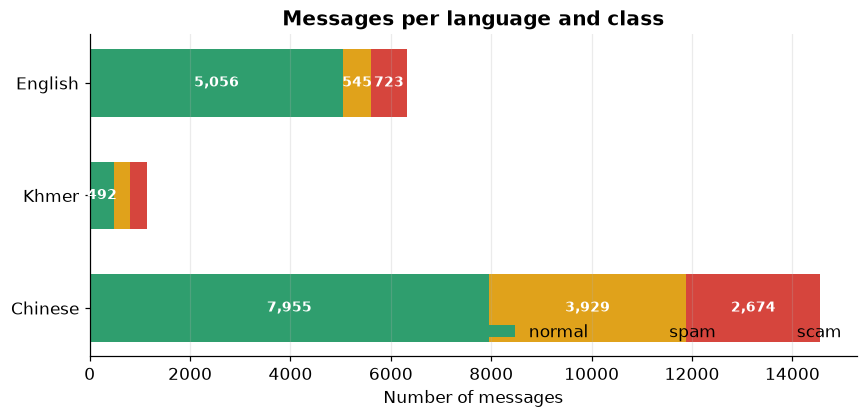

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(LANGS))
for label in LABELS:
    vals = data[data.label == label].lang.value_counts().reindex(LANGS).fillna(0).values
    ax.barh([LANG_NAMES[l] for l in LANGS], vals, left=left, color=LABEL_COLORS[label], label=label, height=0.6)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v > 400:
            ax.text(l + v / 2, y, f"{int(v):,}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += vals
ax.set_xlabel("Number of messages")
ax.set_title("Messages per language and class")
ax.legend(frameon=False, ncol=3, loc="lower right")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
save(fig, "01_class_balance")
plt.show()

Classes are imbalanced (normal messages dominate English and Chinese), and Khmer is much smaller.
We therefore weight every **(language, class)** group equally during training, and we report
**macro F1** and **recall** per language instead of plain accuracy.

### 3.3 What do scams look like? Links, phone numbers and money

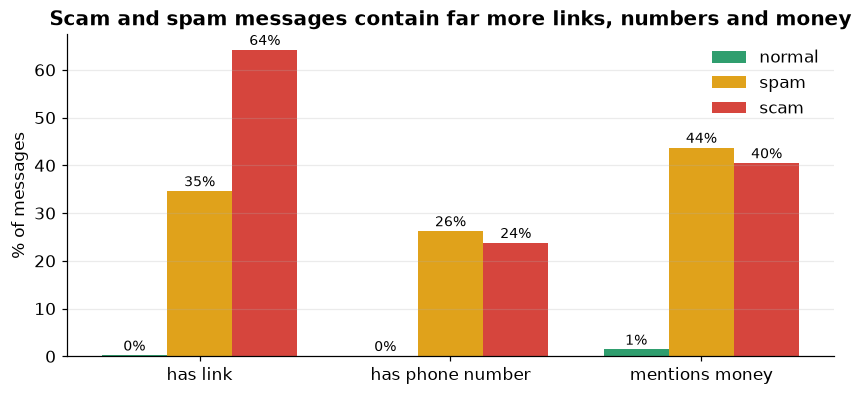

,has link,has phone number,mentions money
label,,,
normal,0.2,0.1,1.4
spam,34.6,26.2,43.7
scam,64.2,23.8,40.5


In [6]:
signals = pd.DataFrame({
    "has link": data.norm.str.contains(URL),
    "has phone number": data.norm.str.contains(PHONE),
    "mentions money": data.text.str.contains(r"[$£€¥៛]|dollar|ដុល្លារ|រៀល|元|万", case=False, regex=True),
    "label": data.label,
})
share = signals.groupby("label")[["has link", "has phone number", "mentions money"]].mean().reindex(LABELS) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(3)
for i, label in enumerate(LABELS):
    bars = ax.bar(x + (i - 1) * 0.26, share.loc[label], 0.26, color=LABEL_COLORS[label], label=label)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.0f}%", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(share.columns)
ax.set_ylabel("% of messages")
ax.set_title("Scam and spam messages contain far more links, numbers and money")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
save(fig, "02_signals")
plt.show()
share.round(1)

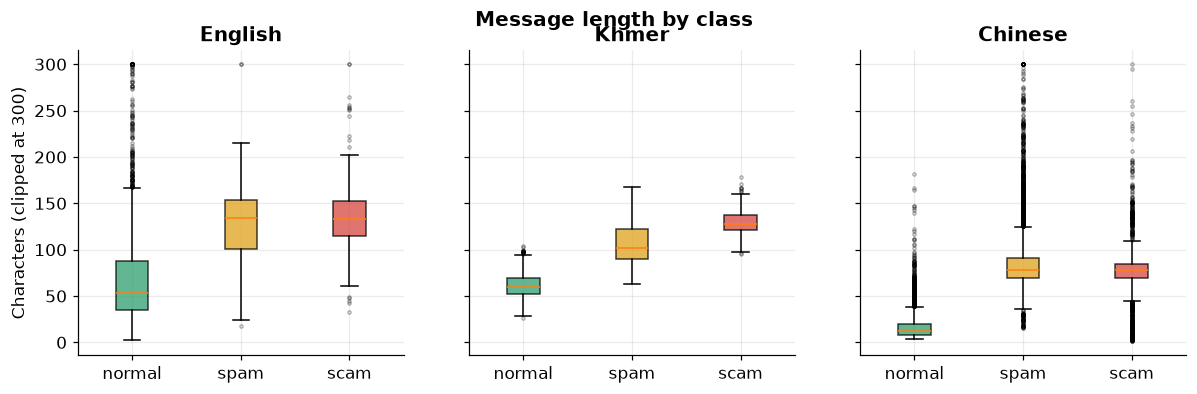

In [7]:
data["length"] = data.text.str.len()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, lang in zip(axes, LANGS):
    sub = data[data.lang == lang]
    parts = [sub[sub.label == l].length.clip(upper=300) for l in LABELS]
    bp = ax.boxplot(parts, tick_labels=LABELS, patch_artist=True, flierprops=dict(markersize=2, alpha=0.3))
    for patch, l in zip(bp["boxes"], LABELS):
        patch.set_facecolor(LABEL_COLORS[l]); patch.set_alpha(0.75)
    ax.set_title(LANG_NAMES[lang])
axes[0].set_ylabel("Characters (clipped at 300)")
fig.suptitle("Message length by class", fontweight="bold")
save(fig, "03_length")
plt.show()

Normal messages are short and personal; spam and scams are longer because they must explain an
"offer" or a "problem" and include a link or number to contact.

## 4. Preprocessing

### 4.1 Normalisation
The same `normalize()` function (in `src/textprep.py`, ported line by line to JavaScript) runs
in training and in the browser:

1. Unicode NFKC and lower-case; traditional → simplified Chinese; Khmer digits ០-៩ → 0-9;
   Khmer spelling variants unified (ឱ្យ → ឲ្យ, េ + ា → ោ, subscript order)
2. Links → a URL placeholder, e-mail → EMAIL placeholder, phone numbers → PHONE placeholder
3. Punctuation removed (currency signs such as $ ៛ ¥ and emoji such as 🎁 ⚠️ are kept)
4. Every number → `0` (so "$500" and "$20" look the same to the model)
5. Spaces between Chinese characters removed

In [8]:
examples = [
    "URGENT! You have WON £1,000. Call 09061743386 or visit http://bit.ly/abc now!!",
    "អបអរសាទរ! លេខទូរស័ព្ទរបស់អ្នកបានឈ្នះ ៥០០ ដុល្លារ។ ចុច http://smart-gift.club/win",
    "【建設銀行】您的賬戶存在異常，請登錄 icbc-verify.top 驗證。",
]
pd.DataFrame({"original": examples,
              "normalised": [normalize(e).replace(URL, "‹URL›").replace(PHONE, "‹PHONE›") for e in examples]})

,original,normalised
0,"URGENT! You have WON £1,000. Call 09061743386 ...",urgent you have won £0 0 call ‹PHONE› or visit...
1,អបអរសាទរ! លេខទូរស័ព្ទរបស់អ្នកបានឈ្នះ ៥០០ ដុល្ល...,អបអរសាទរ លេខទូរស័ព្ទរបស់អ្នកបានឈ្នះ 0 ដុល្លារ ...
2,【建設銀行】您的賬戶存在異常，請登錄 icbc-verify.top 驗證。,建设银行您的账户存在异常请登录 ‹URL› 验证


### 4.2 Why characters, not words?
English separates words with spaces. **Khmer and Chinese do not.** A standard word tokenizer
turns a whole Chinese sentence into one "word", and breaks Khmer at every vowel sign.
Character n-grams (all sequences of 1 to 4 characters) work for every script without a dictionary.

In [9]:
word_tok = TfidfVectorizer(preprocessor=normalize).build_analyzer()
for e in examples:
    print("words:     ", word_tok(e)[:8])
    print("characters:", analyze(e)[40:48], "\n")

words:      ['urgent', 'you', 'have', 'won', 'call', 'or', 'visit', 'now']
characters: [' ', '\ue000', ' ', 'n', 'o', 'w', 'ur', 'rg'] 

words:      ['អបអរស', 'ទរ', 'ខទ', 'រស', 'ទរបស', 'នកប', 'នឈ']
characters: ['ល', '្', 'ល', 'ា', 'រ', ' ', 'ច', 'ុ'] 

words:      ['建设银行您的账户存在异常请登录', '验证']
characters: ['设银行', '银行您', '行您的', '您的账', '的账户', '账户存', '户存在', '存在异'] 



### 4.3 Train / validation / test split

* **Real data**: stratified random split by language and class, 70 / 15 / 15.
* **Authored data**: split **by template**, so the test set only contains message patterns the
  model has never seen (otherwise near-identical variants would leak and inflate the score).

In [10]:
data["split"] = ""
real_idx = data.index[data.source != "authored"]
strat = data.loc[real_idx, "lang"] + "-" + data.loc[real_idx, "label"]
tr, rest = train_test_split(real_idx, test_size=0.30, stratify=strat, random_state=SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=strat.loc[rest], random_state=SEED)
data.loc[tr, "split"], data.loc[va, "split"], data.loc[te, "split"] = "train", "val", "test"

for (lang, label), grp in data[data.source == "authored"].groupby(["lang", "label"]):
    groups = rng.permutation(grp.group.unique())
    n_test = n_val = max(1, round(len(groups) * 0.15))
    assign = {g: "test" for g in groups[:n_test]} | {g: "val" for g in groups[n_test:n_test + n_val]}
    data.loc[grp.index, "split"] = grp.group.map(lambda g: assign.get(g, "train"))

pd.crosstab([data.lang.map(LANG_NAMES), data.label], data.split)[["train", "val", "test"]]

split           train   val  test
lang    label                    
Chinese normal   5572  1205  1178
        scam     1882   394   398
        spam     2762   581   586
English normal   3532   762   762
        scam      516   104   103
        spam      380    88    77
Khmer   normal    323    73    96
        scam      224    52    57
        spam      235    48    33

### 4.4 TF-IDF features
Each message becomes a vector of 40,000 character n-gram weights. TF-IDF gives high weight to
n-grams that are frequent in this message but rare overall. We use sublinear term frequency
(1 + log count) and L2 normalisation.

In [11]:
train, val, test = (data[data.split == s] for s in ("train", "val", "test"))

group_size = train.groupby(["lang", "label"]).size()
weights = train.apply(lambda r: len(train) / (len(group_size) * group_size[(r.lang, r.label)]), axis=1).values

char_vec = TfidfVectorizer(analyzer=analyze, sublinear_tf=True, min_df=2, max_features=40000, dtype=np.float32)
X_train = char_vec.fit_transform(train.text)
X_val, X_test = char_vec.transform(val.text), char_vec.transform(test.text)
y_train, y_val, y_test = train.label.values, val.label.values, test.label.values
print("Character features:", X_train.shape)

word_vec = TfidfVectorizer(preprocessor=normalize, sublinear_tf=True, min_df=2, max_features=40000,
                           ngram_range=(1, 2), dtype=np.float32)
Xw_train = word_vec.fit_transform(train.text)
Xw_val, Xw_test = word_vec.transform(val.text), word_vec.transform(test.text)
print("Word features:", Xw_train.shape)

Character features: (15426, 40000)


Word features: (15426, 13899)


## 5. Models

| Model | Features | Why |
|---|---|---|
| Multinomial **Naive Bayes** | characters | Classic spam-filter baseline |
| **Logistic Regression** | words | What most tutorials do, to show its limits on Khmer/Chinese |
| **Logistic Regression** | characters | Our main model: fast, small, explainable |
| **Neural network (MLP)** | characters | One hidden layer of 64 ReLU units |

The regularisation strength `C` of Logistic Regression is tuned on the validation set.

In [12]:
def macro_f1(model, X, y):
    return f1_score(y, model.predict(X), average="macro")

tuning = []
for C in [1, 3, 10, 30, 100]:
    m = LogisticRegression(C=C, max_iter=2000).fit(X_train, y_train, sample_weight=weights)
    tuning.append({"C": C, "val macro F1": macro_f1(m, X_val, y_val)})
tuning = pd.DataFrame(tuning)
# The scores are almost flat, so we take the strongest regularisation (smallest C) within
# 0.2 points of the best score: simpler models generalise better to new scam wording.
best_C = float(tuning.loc[tuning["val macro F1"] >= tuning["val macro F1"].max() - 0.002, "C"].min())
print(tuning.round(4).to_string(index=False), "\nChosen C:", best_C)

  C  val macro F1
  1        0.9302
  3        0.9362
 10        0.9456
 30        0.9387
100        0.9366 
Chosen C: 10.0


In [13]:
models, train_time = {}, {}

def timed_fit(name, model, X, **kw):
    t0 = time.time()
    models[name] = model.fit(X, y_train, **kw)
    train_time[name] = time.time() - t0

timed_fit("Naive Bayes", MultinomialNB(alpha=0.1), X_train, sample_weight=weights)
timed_fit("LogReg (words)", LogisticRegression(C=best_C, max_iter=2000), Xw_train, sample_weight=weights)
timed_fit("LogReg (characters)", LogisticRegression(C=best_C, max_iter=2000), X_train, sample_weight=weights)
timed_fit("MLP (characters)", MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-4, batch_size=128,
                                            max_iter=30, early_stopping=True, random_state=SEED), X_train)
features = {"Naive Bayes": X_test, "LogReg (words)": Xw_test, "LogReg (characters)": X_test, "MLP (characters)": X_test}
pd.Series(train_time).round(1).rename("training time (s)")

Naive Bayes             0.0
LogReg (words)          0.4
LogReg (characters)     0.8
MLP (characters)       29.0
Name: training time (s), dtype: float64

## 6. Evaluation on the test set

Besides accuracy and macro Precision / Recall / F1, three numbers matter most to a user:
* **Scam recall**: of all real scams, how many do we label "scam"?
* **Warned**: of all scam and spam messages, how many get *any* warning (spam or scam)?
* **False alarms**: of all normal messages, how many do we wrongly flag as spam or scam?

In [14]:
def evaluate(name, sub=None):
    mask = np.ones(len(test), bool) if sub is None else sub
    y = y_test[mask]
    yhat = models[name].predict(features[name][mask])
    p, r, f1, _ = precision_recall_fscore_support(y, yhat, average="macro", zero_division=0)
    return {
        "Accuracy": accuracy_score(y, yhat), "Precision": p, "Recall": r, "Macro F1": f1,
        "Scam recall": (yhat[y == "scam"] == "scam").mean(),
        "Warned (spam or scam)": (yhat[y != "normal"] != "normal").mean(),
        "False alarms": (yhat[y == "normal"] != "normal").mean(),
    }

results = pd.DataFrame({name: evaluate(name) for name in models}).T
results.to_csv(ROOT / "reports" / "model_comparison.csv")
(results * 100).round(1)  # %

,Accuracy,Precision,Recall,Macro F1,Scam recall,Warned (spam or scam),False alarms
Naive Bayes,96.3,95.6,94.8,95.1,87.8,96.3,2.2
LogReg (words),83.0,87.2,71.8,77.0,60.6,62.0,1.8
LogReg (characters),97.4,96.7,95.8,96.2,90.1,97.8,0.8
MLP (characters),97.1,96.9,95.0,95.9,87.8,95.9,0.5


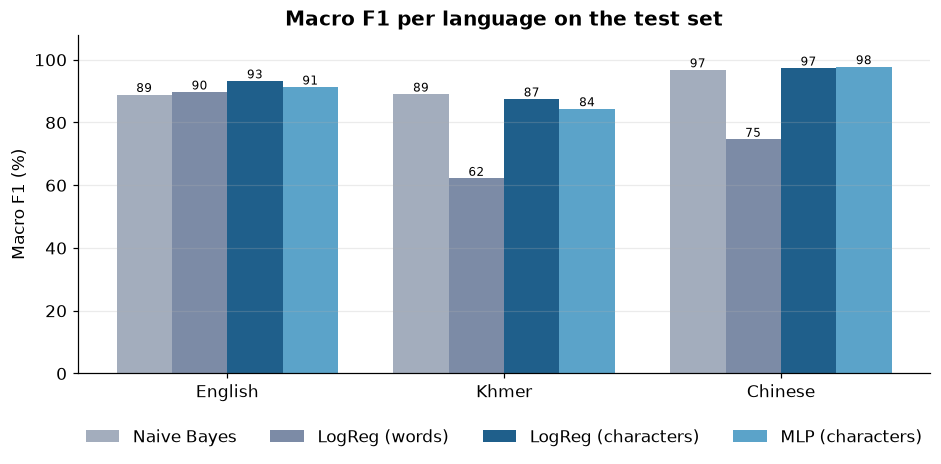

,Naive Bayes,LogReg (words),LogReg (characters),MLP (characters)
English,88.9,89.7,93.2,91.3
Khmer,89.0,62.2,87.5,84.4
Chinese,96.8,74.6,97.3,97.8


In [15]:
per_lang = pd.DataFrame({
    name: {LANG_NAMES[l]: evaluate(name, (test.lang == l).values)["Macro F1"] for l in LANGS} for name in models
})
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.2
for k, name in enumerate(models):
    bars = ax.bar(np.arange(3) + (k - 1.5) * w, per_lang[name] * 100, w, color=MODEL_COLORS[name], label=name)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.0f}", ha="center", fontsize=8)
ax.set_xticks(range(3))
ax.set_xticklabels(per_lang.index)
ax.set_ylabel("Macro F1 (%)")
ax.set_ylim(0, 108)
ax.set_title("Macro F1 per language on the test set")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
save(fig, "04_f1_per_language")
plt.show()
(per_lang * 100).round(1)  # macro F1 %

Word features work for English but fall apart on Chinese and Khmer, where there are no spaces.
Character n-grams fix this. Logistic Regression and the MLP perform similarly; we deploy
**Logistic Regression (characters)** because it is tiny, fast in a browser and **explainable**:
every n-gram has one weight per class, so we can show users *why* a message was flagged.

In [16]:
FINAL = "LogReg (characters)"
final = models[FINAL]
print(classification_report(y_test, final.predict(X_test), digits=3))

              precision    recall  f1-score   support

      normal      0.986     0.992     0.989      2036
        scam      0.973     0.901     0.936       558
        spam      0.941     0.981     0.961       696

    accuracy                          0.974      3290
   macro avg      0.967     0.958     0.962      3290
weighted avg      0.974     0.974     0.974      3290



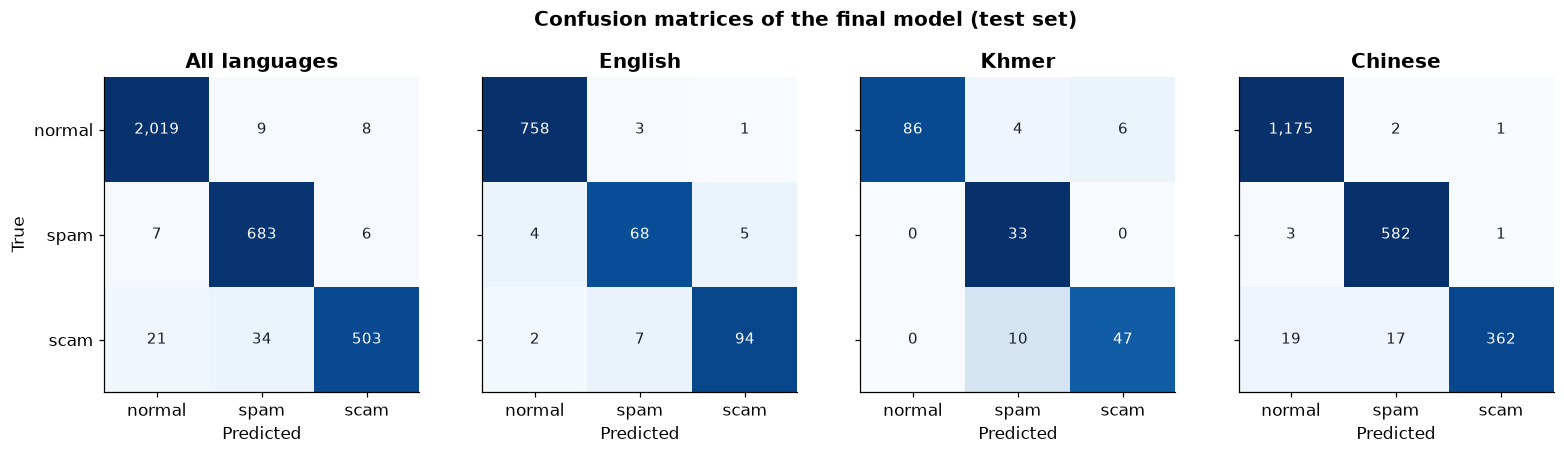

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (title, mask) in zip(axes, [("All languages", np.ones(len(test), bool))] +
                             [(LANG_NAMES[l], (test.lang == l).values) for l in LANGS]):
    cm = confusion_matrix(y_test[mask], final.predict(X_test[mask]), labels=LABELS)
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=10,
                    color="white" if pct[i, j] > 0.55 else INK)
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.grid(False)
    ax.set_xticklabels(LABELS); ax.set_yticklabels(LABELS if ax is axes[0] else [])
    ax.set_xlabel("Predicted")
    ax.set_title(title)
axes[0].set_ylabel("True")
fig.suptitle("Confusion matrices of the final model (test set)", fontweight="bold")
save(fig, "05_confusion_matrices")
plt.show()

### 6.1 Unseen message patterns
The authored test messages come from templates the model never saw. This is the honest score
for Khmer, because all Khmer data is authored.

In [18]:
unseen = (test.source == "authored").values
unseen_scores = pd.DataFrame({LANG_NAMES[l]: evaluate(FINAL, unseen & (test.lang == l).values) for l in LANGS}).T
unseen_scores["test messages"] = [int((unseen & (test.lang == l).values).sum()) for l in LANGS]
unseen_scores.iloc[:, :-1] = (unseen_scores.iloc[:, :-1] * 100).round(1)
unseen_scores

,Accuracy,Precision,Recall,Macro F1,Scam recall,Warned (spam or scam),False alarms,test messages
English,98.8,99.1,99.1,99.1,97.4,97.9,0.0,86
Khmer,89.2,86.3,90.7,87.5,82.5,100.0,10.4,186
Chinese,54.5,63.1,76.2,55.9,28.6,69.4,0.0,44


## 7. What did the model learn?
The n-grams with the largest weights for **scam** in each language.

In [19]:
vocab = np.array(char_vec.get_feature_names_out())
coef = pd.DataFrame(final.coef_, index=final.classes_, columns=vocab)
readable = lambda s: s.replace(URL, "‹URL›").replace(PHONE, "‹PHONE›").replace(EMAIL, "‹EMAIL›")

MIN_LEN = {"en": 4, "km": 4, "zh": 2}
scam_texts = data[data.label == "scam"].norm

def readable_en(gram):
    """Show the most common scam word that contains an English n-gram, e.g. 'erif' → 'verify'."""
    if " " in gram:
        return None
    words = pd.Series(" ".join(scam_texts[scam_texts.str.contains(gram, regex=False)].head(300)).split())
    words = words[words.str.contains(gram, regex=False) & words.str.fullmatch(r"[a-z]{3,12}")]
    return words.value_counts().index[0] if len(words) else None

def top_ngrams(lang, k=12):
    scores = (coef.loc["scam"] - coef.loc["normal"]).sort_values(ascending=False)
    out = []
    for gram in scores.index:
        g = gram.strip()
        if g in (URL, PHONE):
            if lang == "en" and readable(g) not in out:
                out.append(readable(g))
        elif lang == "km" and not ("ក" <= g[0] <= "ឳ" and g[-1] != "្"):
            continue                       # skip fragments that start mid-syllable
        elif len(g) >= MIN_LEN[lang] and detect_language(g) == lang and URL not in g and PHONE not in g:
            label = readable_en(g) if lang == "en" else g
            if label and not any(label in o or o in label for o in out):
                out.append(label)
        if len(out) == k:
            break
    return out

pd.DataFrame({LANG_NAMES[l]: top_ngrams(l) for l in LANGS})

,English,Khmer,Chinese
0,‹PHONE›,អ្នក,微信
1,‹URL›,ក្នុ,邮政
2,claim,ត្រូ,农行
3,prize,រាន់,银行
4,call,គ្រា,卡号
5,free,រូវប,换号
6,chat,គណនី,姓名
7,customer,ន់តែ,敬的
8,phone,ផ្ទេ,尊敬
9,online,នឹងត,投资


Nobody gave the model a list of scam words; it found them itself. In English: links, phone
numbers, "claim", "call", "prize", "free", "code". In Khmer: "គណនី" (account), "ផ្ញើ" (send),
"រង្វាន់" (prize), "អ្នក" (you). In Chinese: 微信 (WeChat), 换号 (changed my number),
卡号 (card number), bank names such as 农行 and 建行, and 基金 (fund).
(Khmer columns show 4-character pieces, so some are parts of longer words.)

### 7.1 Mistakes

In [20]:
pred = final.predict(X_test)
proba = final.predict_proba(X_test).max(axis=1)
errors = test.assign(pred=pred, confidence=proba)[pred != y_test]
errors.sort_values("confidence", ascending=False)[["lang", "label", "pred", "confidence", "text"]].head(12)

,lang,label,pred,confidence,text
3667,en,scam,spam,0.989943,"Update_Now - Xmas Offer! Latest Motorola, Sony..."
4306,en,scam,spam,0.986820,U are subscribed to the best Mobile Content Se...
17987,zh,scam,normal,0.984937,不好意思 少 了 一位 应为
1640,en,scam,spam,0.983328,XCLUSIVE@CLUBSAISAI 2MOROW 28/5 SOIREE SPECIAL...
17907,zh,scam,normal,0.978949,我 马上 要 换 号 了 到时候 你 就 联系 不到 我 了 我 把 比邻 那个 软件 卸载 了
17985,zh,scam,normal,0.958455,祝 董事长 在 新 的 一年 里 心想事成 财运亨通 身体健康 万事如意 想 你 的 刚子 ...
3168,en,scam,spam,0.958032,Natalja (25/F) is inviting you to be her frien...
17906,zh,scam,normal,0.945004,婷婷
8970,zh,normal,spam,0.928479,春天与你一起约惠，凭本人学生证及此短信 <#> 元即可入住长沙丽湖天马大酒店！活动时间3月8...
4615,en,spam,normal,0.927514,"Latest News! Police station toilet stolen, cop..."


## 8. Export the model for the web app

The browser recreates the TF-IDF vector with the same normaliser and n-grams, then computes
`softmax(W·x + b)`. We export the vocabulary, IDF weights and coefficients, and a reference set of
messages to check that the JavaScript gives identical results.

In [21]:
import shutil  # noqa: E402

vocab_list = char_vec.get_feature_names_out().tolist()
n = len(vocab_list)
blob = np.concatenate([char_vec.idf_.astype("<f4"), final.coef_.astype("<f4").ravel()])
blob.tofile(WEB / "model.bin")
row = results.loc[FINAL]
meta = {
    "classes": final.classes_.tolist(), "n_features": n, "ngram_range": [1, 4],
    "layout": "float32: idf[n_features], then coef[n_classes][n_features]",
    "intercept": final.intercept_.round(6).tolist(), "vocab": vocab_list,
    "metrics": {k: round(float(v), 6) for k, v in row.items()},
    "per_language": {l: {k: round(float(v), 6) for k, v in evaluate(FINAL, (test.lang == l).values).items()}
                     | {"n": int((test.lang == l).sum())} for l in LANGS},
    "n_test": int(len(test)),
    "trained_on": int(len(train)),
}
(WEB / "model.json").write_text(json.dumps(meta, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
shutil.copy(ROOT / "src" / "t2s.json", WEB / "t2s.json")

ref = test.groupby(["lang", "label"]).head(10)
reference = [{"text": t, "norm": normalize(t), "proba": final.predict_proba(char_vec.transform([t]))[0].round(6).tolist()}
             for t in ref.text]
(WEB / "reference.json").write_text(json.dumps(reference, ensure_ascii=False), encoding="utf-8")

# Example messages for the app's "Try an example" buttons (from the test set, never trained on)
for f in ("model.json", "model.bin", "t2s.json"):
    print(f, f"{(WEB / f).stat().st_size / 1024:,.0f} KB")

model.json 374 KB
model.bin 625 KB
t2s.json 50 KB


## 9. Conclusion

* One multilingual model handles **English, Khmer and Chinese** thanks to character n-grams:
  no word segmentation, no translation, no language-specific code. On the test set it reaches
  97.4% accuracy and 96.2% macro F1, catches 90.1% of scams (97.8% get some warning) and wrongly
  flags only 0.8% of normal messages.
* Word-based features, the usual tutorial approach, clearly fail on Khmer (62% macro F1) and
  Chinese (75%), against 88% and 97% with characters.
* Logistic Regression beats the neural network (96.2% vs 95.9% macro F1) while staying
  explainable and small enough to run in a phone browser. Naive Bayes is slightly better on Khmer (89% vs 88%).
* On authored message patterns it has never seen, it reaches 99% macro F1 in English and 88% in
  Khmer, but only 56% on the 44 Chinese test messages: two Chinese scam patterns ("my new number,
  send money" and parcel re-delivery fees) are rare in the real Chinese data. Our first version
  scored only 28% on modern English scams, because the public English data is from the 2010s;
  adding modern patterns (delivery fees, toll fines, job offers, account locks) fixed most of it.
* **Limitations**: the Khmer data is authored by us, so Khmer scores show how well the model
  generalises to new patterns, not proven real-world accuracy. The Chinese data comes from
  fake-base-station spam in China and personal SMS from Singapore, so it may differ from scams in
  Cambodia. Scammers change their wording quickly, so the model needs regular retraining.
* **Next steps**: collect real Khmer scam messages (with consent) from classmates and the public,
  add Telegram/Facebook messages, and let users report mistakes.